In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the raw file
df = pd.read_csv("../data/raw/WA_Fn-UseC_-HR-Employee-Attrition.csv")
# Drop the 3 columns that have same value for everyone
df_clean = df.drop(columns=["EmployeeCount","Over18","StandardHours"])
# 1 = left, 0 = stayed. The mean of this column is the attrition rate.
df_clean["AttritionFlag"] = (df_clean["Attrition"] == "Yes").astype(int)
df_clean.shape

(1470, 33)

In [3]:
# Age bands; pd.cut splits numbers into ranges
df_clean["AgeBand"] = pd.cut(df_clean["Age"],bins=[17,25,35,45,60],labels=["18-25","26-35","36-45","46-60"])
# Tenure bands ( years at this company) 
df_clean["TenureBand"] = pd.cut(df_clean["YearsAtCompany"],bins=[-1,2,5,10,40],labels=["0-2 yrs","3-5 yrs","6-10 yrs","11+ yrs"])
# Income quartiles: pd.qcut splits into 4 groups of EQUAL SIZE
df_clean["IncomeBand"] = pd.qcut(df_clean["MonthlyIncome"],q=4,labels=["Q1 Lowest","Q2","Q3","Q4 Highest"])
df_clean["AgeBand"].value_counts()

                        

AgeBand
26-35    606
36-45    468
46-60    273
18-25    123
Name: count, dtype: int64

In [4]:
df_clean.to_csv("../data/processed/hr_clean.csv",index=False)

In [5]:
def attrition_by(column):
    # Group employees by the chosen column; count, leavers, rate
    table = df_clean.groupby(column,observed=True)["AttritionFlag"].agg(["count","sum","mean"])
    # Give the column clear names
    table.columns = ["Headcount","Leavers","AttritionRate"]
    # Turn 0.161 into 16.1 (a percentage), rounded to 1 decimal point
    table["AttritionRate"] = (table["AttritionRate"]*100).round(1)
    # Highest attrition first
    return table.sort_values("AttritionRate",ascending=False)

In [6]:
attrition_by("Department")

,Headcount,Leavers,AttritionRate
Department,,,
Sales,446,92,20.6
Human Resources,63,12,19.0
Research & Development,961,133,13.8


In [7]:
attrition_by("OverTime")

,Headcount,Leavers,AttritionRate
OverTime,,,
Yes,416,127,30.5
No,1054,110,10.4


In [8]:
attrition_by("JobRole")

,Headcount,Leavers,AttritionRate
JobRole,,,
Sales Representative,83,33,39.8
Laboratory Technician,259,62,23.9
Human Resources,52,12,23.1
Sales Executive,326,57,17.5
Research Scientist,292,47,16.1
Healthcare Representative,131,9,6.9
Manufacturing Director,145,10,6.9
Manager,102,5,4.9
Research Director,80,2,2.5


In [9]:
attrition_by("AgeBand")

,Headcount,Leavers,AttritionRate
AgeBand,,,
18-25,123,44,35.8
26-35,606,116,19.1
46-60,273,34,12.5
36-45,468,43,9.2


In [10]:
attrition_by("TenureBand")

,Headcount,Leavers,AttritionRate
TenureBand,,,
0-2 yrs,342,102,29.8
3-5 yrs,434,60,13.8
6-10 yrs,448,55,12.3
11+ yrs,246,20,8.1


In [11]:
attrition_by("IncomeBand")

,Headcount,Leavers,AttritionRate
IncomeBand,,,
Q1 Lowest,369,108,29.3
Q2,366,52,14.2
Q3,367,39,10.6
Q4 Highest,368,38,10.3


In [12]:
attrition_by("JobLevel")

,Headcount,Leavers,AttritionRate
JobLevel,,,
1,543,143,26.3
3,218,32,14.7
2,534,52,9.7
5,69,5,7.2
4,106,5,4.7


In [13]:
attrition_by("JobSatisfaction")

,Headcount,Leavers,AttritionRate
JobSatisfaction,,,
1,289,66,22.8
3,442,73,16.5
2,280,46,16.4
4,459,52,11.3


In [14]:
attrition_by("EnvironmentSatisfaction")

,Headcount,Leavers,AttritionRate
EnvironmentSatisfaction,,,
1,284,72,25.4
2,287,43,15.0
3,453,62,13.7
4,446,60,13.5


In [15]:
attrition_by("WorkLifeBalance")

,Headcount,Leavers,AttritionRate
WorkLifeBalance,,,
1,80,25,31.2
4,153,27,17.6
2,344,58,16.9
3,893,127,14.2


In [16]:
attrition_by("BusinessTravel")

,Headcount,Leavers,AttritionRate
BusinessTravel,,,
Travel_Frequently,277,69,24.9
Travel_Rarely,1043,156,15.0
Non-Travel,150,12,8.0


In [17]:
attrition_by("MaritalStatus")

,Headcount,Leavers,AttritionRate
MaritalStatus,,,
Single,470,120,25.5
Married,673,84,12.5
Divorced,327,33,10.1


In [18]:
attrition_by("StockOptionLevel")

,Headcount,Leavers,AttritionRate
StockOptionLevel,,,
0,631,154,24.4
3,85,15,17.6
1,596,56,9.4
2,158,12,7.6


In [19]:
attrition_by("Gender")

,Headcount,Leavers,AttritionRate
Gender,,,
Male,882,150,17.0
Female,588,87,14.8


In [20]:
df_clean.groupby("Attrition")[["MonthlyIncome","Age","YearsAtCompany","TotalWorkingYears","DistanceFromHome"]].median()

,MonthlyIncome,Age,YearsAtCompany,TotalWorkingYears,DistanceFromHome
Attrition,,,,,
No,5204.0,36.0,6.0,10.0,7.0
Yes,3202.0,32.0,3.0,7.0,9.0


In [21]:
pd.crosstab(
    df_clean["OverTime"],
    df_clean["Department"],
    values=df_clean["AttritionFlag"],
    aggfunc="mean"
).round(3)*100

Department,Human Resources,Research & Development,Sales
OverTime,,,
No,15.2,8.6,13.8
Yes,29.4,27.3,37.5


## Key findings
- The overall attrition rate in the data set: 16.1% (237 out of 1,470).
- Overtime work: the most prominent pattern of all is an increase in the rate of 30.5% with overtime compared to 10.4% without it, and the difference is true in all three departments.
- Early attrition: 29.8% attrition rate among the 0-2 years' tenure, 35.8% among those aged 18-25, 26.3% among those at Job Level 1.
- Income: those in the lowest income quartile have an attrition rate of 29.3% versus only 10% in the other two quartiles.
- Sales Representatives (39.8%, 83 people) and Laboratory Technicians (23.9%, 259 people) are the highest risk occupations.
- Low job/environment satisfaction and travel frequency increase attrition.

All these are associations rather than causations. In many cases, these factors tend to overlap (young employees have lower job levels, low pay and less seniority).

In [22]:
def chart(column, title, filename, keep_order=False):
    table = attrition_by(column)
    # For bands, keep natural order (young -> old) instead of sorting by rate
    if keep_order:
        table = table.sort_index()
    ax = table["AttritionRate"].plot(kind="bar", color="steelblue", figsize=(8, 4))
    # Red dashed line at the overall rate, for comparison
    ax.axhline(16.1, color="red", linestyle="--", label="Overall 16.1%")
    ax.set_title(title)
    ax.set_ylabel("Attrition rate (%)")
    ax.set_xlabel("")
    ax.legend()
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig("../visualisations/" + filename, dpi=150)
    plt.show()
    

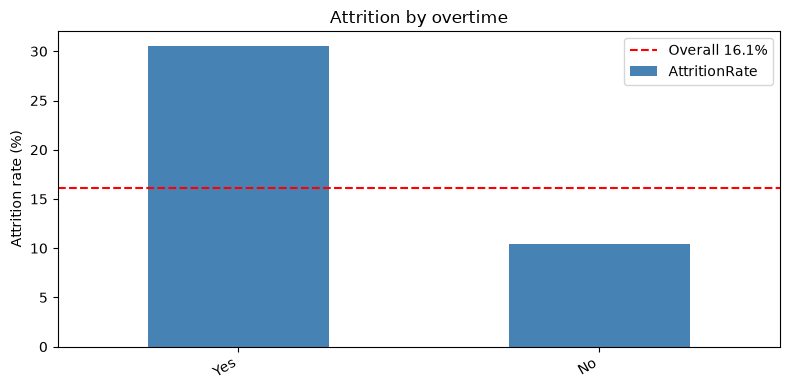

In [23]:
chart("OverTime", "Attrition by overtime", "01_overtime.png")

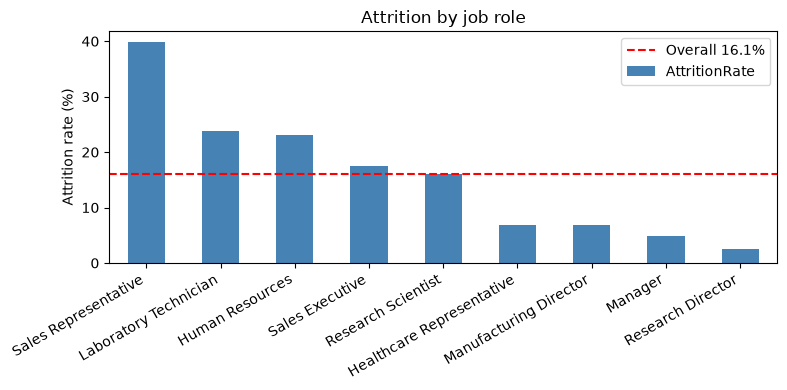

In [24]:
chart("JobRole", "Attrition by job role", "02_jobrole.png")

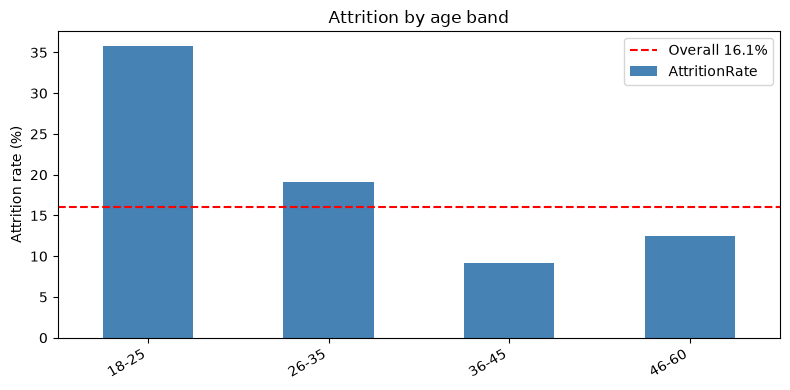

In [25]:
chart("AgeBand", "Attrition by age band", "03_age.png", keep_order=True)

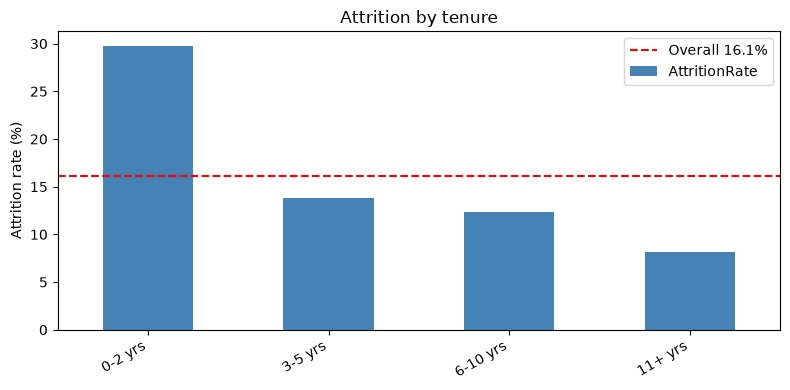

In [26]:
chart("TenureBand", "Attrition by tenure", "04_tenure.png", keep_order=True)

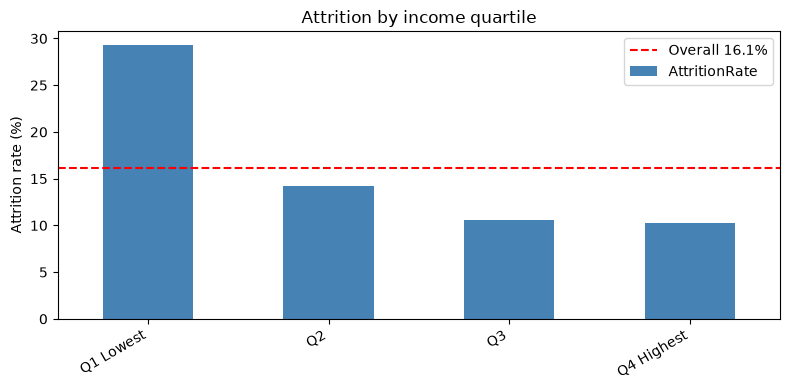

In [27]:
chart("IncomeBand", "Attrition by income quartile", "05_income.png", keep_order=True)